# Linking notable individuals to historical polities, 3500 BCE to 2024
## Getting started with the full dataset (DuckDB)

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from shapely.geometry import shape


## 1. Download the DuckDB file from Zenodo (13.7 GB: the download can take a long time)

In [2]:
DATABASE = Path("data/cultura/cultura_database_V4.duckdb")

if not DATABASE.exists():  # downloads cultura_database_V4.duckdb (13.7 GB) through the Zenodo API and checks its checksum
    subprocess.run([sys.executable, "scripts/download_data.py", "duckdb"], check=True)


## 2. Open the database

In [3]:
con = duckdb.connect(str(DATABASE), read_only=True)

tables = [name for (name,) in con.execute("SELECT table_name FROM duckdb_tables() ORDER BY table_name").fetchall()]
con.execute(" UNION ALL ".join(f"SELECT '{name}' AS table, count(*) AS rows FROM {name}" for name in tables) + " ORDER BY rows DESC").pl()


table,rows
str,i64
"""individual_work""",38487016
"""individual_identifier""",36880376
"""work""",17050395
"""individual_sitelink""",15543581
"""individual""",13002840
…,…
"""occupation""",18227
"""identifier""",10198
"""polity""",1637


## 3. The life stages of one individual

In [4]:
con.execute("""
    SELECT entity.label_en AS name,
           birth_date.year AS birth,
           start_of_active_life.year AS active_from,
           end_of_active_life.year AS active_to,
           death_date.year AS death,
           list_transform(pre_active_life_polity, match -> match.polity.name) AS pre_active,
           list_transform(active_life_polity, match -> match.polity.name) AS active,
           list_transform(post_active_life_polity, match -> match.polity.name) AS post_active
    FROM individual_enriched
    WHERE entity.qid = 'Q7186'  -- Marie Curie
""").pl()


name,birth,active_from,active_to,death,pre_active,active,post_active
str,i64,i64,i64,i64,list[str],list[str],list[str]
"""Marie Curie""",1867,1900,1933,1934,"[""Russian Empire""]","[""French Third Republic""]","[""French Third Republic""]"


## 4. Use case: the Ming dynasty

In [5]:
POLITY = "Ming Dynasty"

con.execute("""
    CREATE OR REPLACE TEMP TABLE ming AS
    SELECT entity.qid AS qid, entity.label_en AS name, birth_date.year AS birth, death_date.year AS death,
           start_of_active_life.year AS active_from, end_of_active_life.year AS active_to
    FROM individual_enriched
    WHERE list_contains(list_transform(active_life_polity, match -> match.polity.name), $polity)
""", {"polity": POLITY})

print(f"Individuals active in the Ming dynasty: {con.execute('SELECT count(*) FROM ming').fetchone()[0]:,}")
con.execute("SELECT * FROM ming LIMIT 10").pl()


Individuals active in the Ming dynasty: 16,571


qid,name,birth,death,active_from,active_to
str,str,i64,i64,i64,i64
"""Q1005462""","""Chen Jiru""",1558,1639,1588,1611
"""Q1017028""","""Zhou Lianggong""",1612,1672,1641,1665
"""Q1022213""","""Cheng Jiasui""",1565,1643,1632,1639
"""Q10263178""","""Wu Zhen""",1328,1379,1364,1379
"""Q10268371""","""Jin Youzi""",1368,1431,1399,1423
"""Q10273604""","""Zuo Menggeng""",1595,1654,1633,1652
"""Q10294099""","""Zhang Keshi""",1591,1654,1621,1644
"""Q10295584""","""Zhang Mengjian""",1338,1403,1375,1398
"""Q10295891""","""Chou Zhang""",1577,1643,1607,1630


## 5. Ming individuals active over time

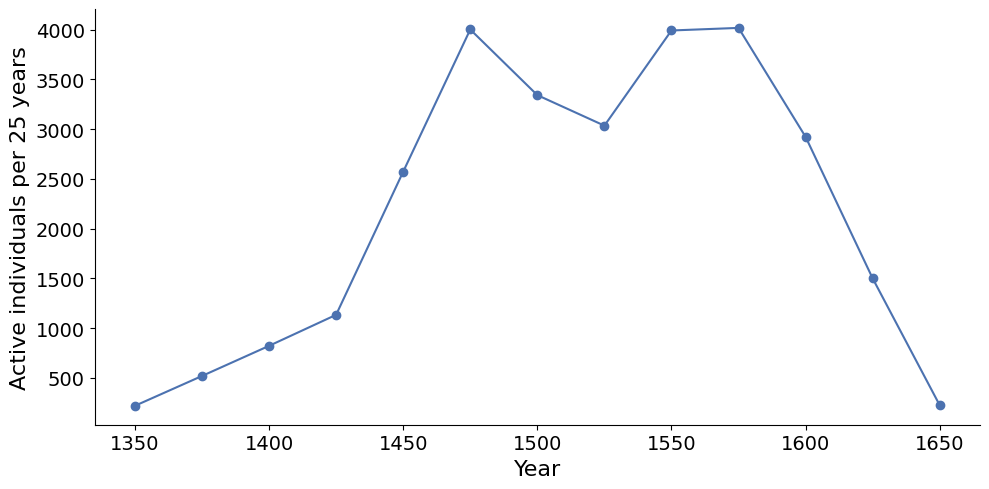

In [6]:
BIN = 25  # years

active_by_bin = con.execute("""
    SELECT bin, count(*) AS individuals
    FROM ming, unnest(range(active_from // $bin * $bin, active_to // $bin * $bin + $bin, $bin)) AS t(bin)
    WHERE bin BETWEEN 1350 AND 1650
    GROUP BY bin ORDER BY bin
""", {"bin": BIN}).pl()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(active_by_bin["bin"], active_by_bin["individuals"], marker="o", color="#4C72B0")
ax.set_xlabel("Year", fontsize=16)
ax.set_ylabel(f"Active individuals per {BIN} years", fontsize=16)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


## 6. Most frequent occupations in the Ming dynasty

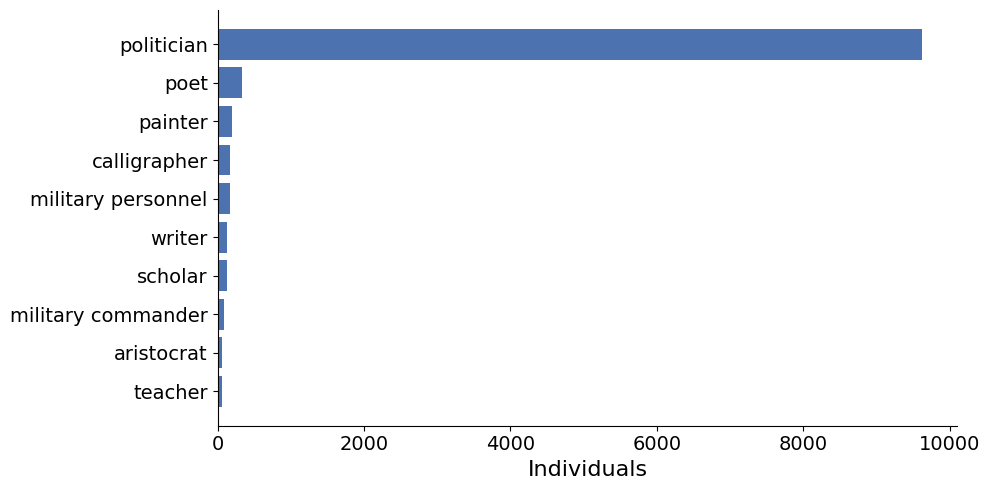

In [7]:
occupations = con.execute("""
    SELECT occupation.entity.label_en AS occupation, count(*) AS individuals
    FROM ming
    JOIN individual ON individual.entity.qid = ming.qid, unnest(individual.occupation) AS t(held)
    JOIN occupation ON occupation.entity.qid = held.entity.qid
    GROUP BY 1 ORDER BY individuals DESC LIMIT 10
""").pl()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(occupations["occupation"].reverse(), occupations["individuals"].reverse(), color="#4C72B0")
ax.set_xlabel("Individuals", fontsize=16)
ax.tick_params(labelsize=14)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


## 7. Active polities of the Chinese world over time

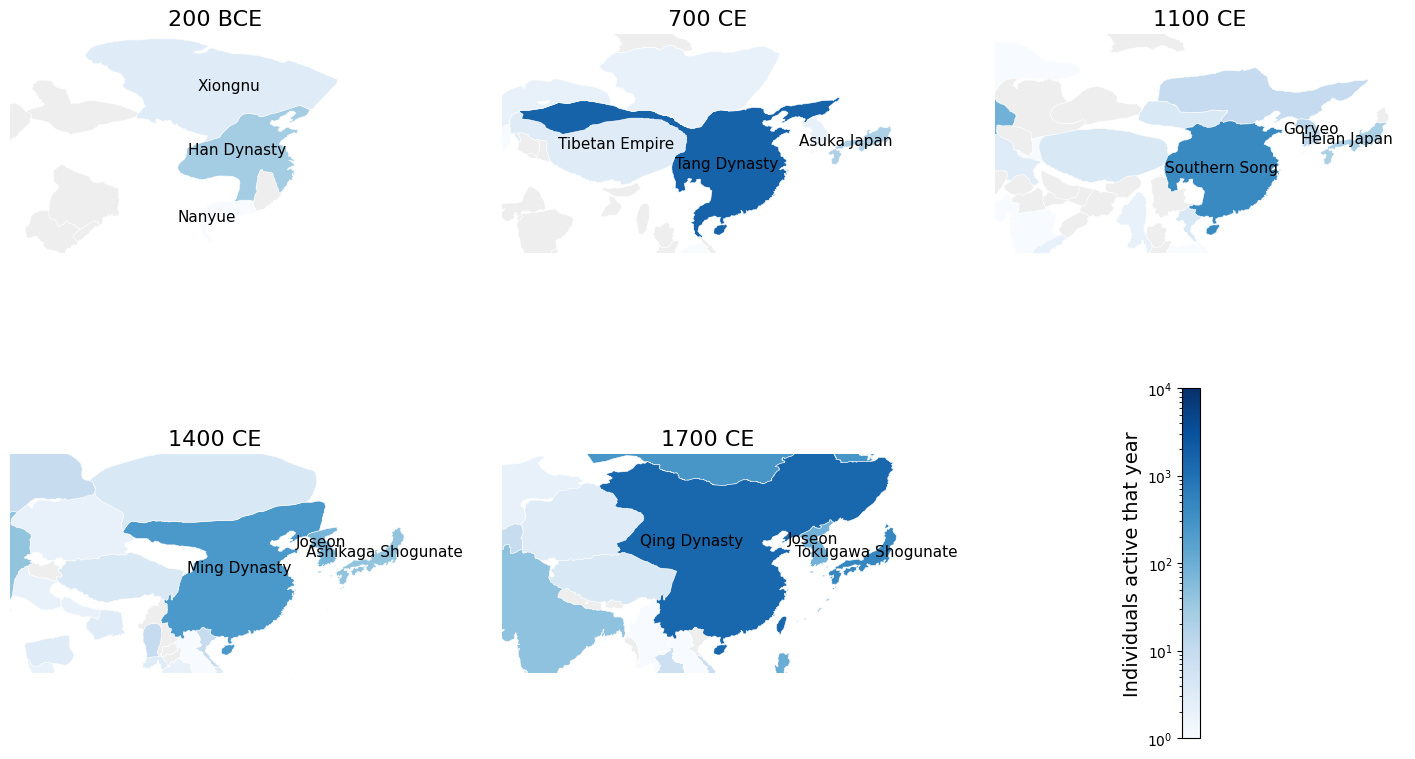

In [8]:
SNAPSHOTS = {-200: "200 BCE", 700: "700 CE", 1100: "1100 CE", 1400: "1400 CE", 1700: "1700 CE"}  # Han, Tang, Song, Ming and Qing
EAST_ASIA = (70, 15, 145, 55)  # longitude and latitude bounds

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
axes[-1].set_axis_off()
norm = LogNorm(vmin=1, vmax=10_000)
for ax, (year, label) in zip(axes, SNAPSHOTS.items()):
    territories = con.execute("""
        SELECT polity.cliopatria_id, polity.name, territory.geometry
        FROM polity, unnest(polity.territories) AS t(territory)
        WHERE territory.start_year <= $year AND territory.end_year >= $year
    """, {"year": year}).pl()
    counts = con.execute("""
        SELECT match.polity.cliopatria_id AS cliopatria_id, count(*) AS individuals
        FROM individual_enriched, unnest(active_life_polity) AS t(match)
        WHERE start_of_active_life.year <= $year AND end_of_active_life.year >= $year
        GROUP BY cliopatria_id
    """, {"year": year}).pl()
    shapes = gpd.GeoDataFrame(
        territories.join(counts, on="cliopatria_id", how="left").drop("geometry").to_pandas(),
        geometry=[shape(json.loads(geometry)) for geometry in territories["geometry"]],
    ).cx[EAST_ASIA[0]:EAST_ASIA[2], EAST_ASIA[1]:EAST_ASIA[3]]
    shapes.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.4)
    shown = shapes.dropna(subset=["individuals"])
    shown.plot(ax=ax, column="individuals", cmap="Blues", norm=norm, edgecolor="white", linewidth=0.4)
    shown = shown.assign(point=shown.geometry.representative_point())
    shown = shown[shown["point"].x.between(EAST_ASIA[0], EAST_ASIA[2]) & shown["point"].y.between(EAST_ASIA[1], EAST_ASIA[3])]
    for _, polity in shown.nlargest(3, "individuals").iterrows():
        ax.annotate(polity["name"], (polity["point"].x, polity["point"].y), ha="center", fontsize=11)
    ax.set_xlim(EAST_ASIA[0], EAST_ASIA[2])
    ax.set_ylim(EAST_ASIA[1], EAST_ASIA[3])
    ax.set_title(label, fontsize=16)
    ax.set_axis_off()
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="Blues"), ax=axes[-1], fraction=0.5, location="left")
colorbar.set_label("Individuals active that year", fontsize=14)
plt.show()
